# GUIDE Dataset — Standalone CatBoost Baseline

Target: `IncidentGrade` (TruePositive / BenignPositive / FalsePositive), 3-class classification.

Scope for this notebook:
- Train and evaluate **CatBoost only**, as a third baseline alongside the existing LightGBM and Logistic Regression results — no ensembling here.
- Reuse the exact same cleaned dataset, audited feature set, and train/validation split saved by the LightGBM notebook (`guide-lightgbm-baseline`), mounted here via `kernel_sources`. Row alignment and `(OrgId, IncidentId)` group non-overlap are re-verified, not assumed.
- CatBoost's **native categorical handling** is used directly on raw categorical values — this notebook does **not** reuse Logistic Regression's one-hot encoded sparse matrix.
- A known risk from an earlier, separate ensemble notebook: passing many categorical columns to CatBoost with default settings triggers automatic pairwise/triple/quadruple categorical-combination statistics (`max_ctr_complexity` default 4), which made that run impractically slow (only 46/500 iterations in ~33 minutes, ~5.3h projected). This notebook explicitly sets `max_ctr_complexity=1` to avoid that blowup while still using CatBoost's native per-column categorical handling.
- The official `GUIDE_Test.csv` is **not loaded** — it stays untouched for a later, unbiased final comparison across models.

In [1]:
import os, glob, time, json, warnings, shutil, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from catboost import CatBoostClassifier, Pool
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

OUT_DIR = '/kaggle/working'
os.makedirs(OUT_DIR, exist_ok=True)

t0 = time.time()
def lap(msg):
    print(f'[{time.time() - t0:7.1f}s] {msg}')

## 1. Load data and reproduce the LightGBM notebook's cleaning

Only `GUIDE_Train.csv` is loaded. The exact same cleaning steps as the LightGBM notebook (drop duplicate rows, then drop rows with a missing target) are applied, in the same order, so this produces the identical row set (by `Id`) that `split_assignment.csv` was built from. A fresh sequential `row_id` is also assigned right after cleaning — it is deterministic given identical input/cleaning, so it will line up with the same column saved by any other notebook using this exact pipeline, and is saved with validation predictions below as a stable join key for future ensembling.

In [2]:
matches = glob.glob('/kaggle/input/**/GUIDE_Train.csv', recursive=True)
if not matches:
    raise FileNotFoundError('GUIDE_Train.csv not found under /kaggle/input')
DATA_DIR = os.path.dirname(matches[0])
lap(f'Using DATA_DIR = {DATA_DIR}')

TARGET = 'IncidentGrade'

df = pd.read_csv(f'{DATA_DIR}/GUIDE_Train.csv')
lap(f'Loaded raw train = {df.shape}')

df = df.drop_duplicates().reset_index(drop=True)
lap(f'After dropping duplicate rows: {df.shape}')

df = df.dropna(subset=[TARGET]).reset_index(drop=True)
lap(f'After dropping rows with missing target: {df.shape}')

df['row_id'] = np.arange(len(df))

assert df[TARGET].notna().all()
print('Class distribution:')
print(df[TARGET].value_counts())

[    0.5s] Using DATA_DIR = /kaggle/input/datasets/Microsoft/microsoft-security-incident-prediction
[   42.0s] Loaded raw train = (9516837, 45)
[   74.3s] After dropping duplicate rows: (9494278, 45)
[   78.3s] After dropping rows with missing target: (9442956, 45)
Class distribution:
IncidentGrade
BenignPositive    4110748
TruePositive      3302644
FalsePositive     2029564
Name: count, dtype: int64


## 2. Reuse the audited feature set from the LightGBM notebook

`preprocessing_info.json` (saved by `guide-lightgbm-baseline`, mounted here as a kernel source) records the leakage review already performed: identifiers/hashes excluded, `ActionGrouped`/`ActionGranular` excluded as remediation-action leakage, and `SuspicionLevel`/`LastVerdict` reviewed and kept under the documented assumption that they are automated, pre-triage detection outputs rather than a restatement of the final grade. **That assumption is not re-verified here** — it remains an open, unresolved question about exact prediction-time availability, carried over unchanged from the LightGBM notebook. The feature set itself is identical (same 19 raw columns), so this result is directly comparable to LightGBM on that axis; what differs from both LightGBM and Logistic Regression is purely how the 5 numeric-but-really-categorical columns are *encoded* (see section 5).

In [3]:
prep_matches = glob.glob('/kaggle/input/**/preprocessing_info.json', recursive=True)
if not prep_matches:
    raise FileNotFoundError('preprocessing_info.json not found under /kaggle/input — '
                            'check that kernel_sources includes guide-lightgbm-baseline')
with open(prep_matches[0]) as f:
    lgb_preprocessing_info = json.load(f)
lap(f'Loaded preprocessing_info.json from {prep_matches[0]}')

CATEGORICAL_COLS = lgb_preprocessing_info['categorical_cols']
NUMERIC_COLS = lgb_preprocessing_info['numeric_cols']
ID_LIKE_COLS = lgb_preprocessing_info['excluded_id_cols']
LEAKAGE_COLS = lgb_preprocessing_info['excluded_leakage_cols']
GROUP_COLS = lgb_preprocessing_info['group_cols']
FEATURES = CATEGORICAL_COLS + NUMERIC_COLS

print('Categorical features (reused):', len(CATEGORICAL_COLS), CATEGORICAL_COLS)
print('Numeric features (reused):', len(NUMERIC_COLS), NUMERIC_COLS)
print('Excluded as identifiers/hashes:', len(ID_LIKE_COLS))
print('Excluded as remediation-action leakage:', LEAKAGE_COLS)
print('Total reused features:', len(FEATURES))
assert set(FEATURES) == set(lgb_preprocessing_info['features']), 'Feature set mismatch vs LightGBM notebook!'

# Drop every raw column we will never use (high-cardinality identifier/hash columns,
# e.g. Sha256, Url, AccountSid, ...) now that dedup/target-cleaning already ran on the
# full column set. This happens *after* the cleaning above, so it does not change
# which rows survive (still identical to the LightGBM notebook's row set) — it only
# frees memory those unused columns were holding before the heavier steps below.
DERIVED_COLS = ['Hour', 'DayOfWeek', 'MitreCount', 'MitrePrimary']
RAW_NEEDED_COLS = ['row_id', 'Id', 'OrgId', 'IncidentId', TARGET, 'Timestamp', 'MitreTechniques'] + \
    [c for c in FEATURES if c not in DERIVED_COLS]
before_cols = df.shape[1]
df = df[RAW_NEEDED_COLS].copy()
gc.collect()
lap(f'Dropped unused raw columns: {before_cols} -> {df.shape[1]} columns, {df.shape[0]} rows unchanged')

[   79.1s] Loaded preprocessing_info.json from /kaggle/input/notebooks/towsifhassan1132/guide-lightgbm-baseline/preprocessing_info.json
Categorical features (reused): 11 ['Category', 'EntityType', 'EvidenceRole', 'ResourceType', 'Roles', 'OSFamily', 'OSVersion', 'AntispamDirection', 'SuspicionLevel', 'LastVerdict', 'MitrePrimary']
Numeric features (reused): 8 ['DetectorId', 'AlertTitle', 'CountryCode', 'State', 'City', 'Hour', 'DayOfWeek', 'MitreCount']
Excluded as identifiers/hashes: 25
Excluded as remediation-action leakage: ['ActionGrouped', 'ActionGranular']
Total reused features: 19
[   81.9s] Dropped unused raw columns: 46 -> 22 columns, 9442956 rows unchanged


## 3. Feature engineering (identical to the LightGBM notebook)

`Timestamp` → `Hour`/`DayOfWeek`; `MitreTechniques` (semicolon-separated string) → count + primary technique. Same logic, same column names.

In [4]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
df['Hour'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek

mitre = df['MitreTechniques'].fillna('')
df['MitreCount'] = mitre.apply(lambda s: 0 if s == '' else len(s.split(';')))
df['MitrePrimary'] = mitre.apply(lambda s: s.split(';')[0] if s != '' else 'None')

lap(f'Engineered features. Feature count: {len(FEATURES)}')

[   94.8s] Engineered features. Feature count: 19


## 4. Load and verify the saved train/validation split

`split_assignment.csv` (also mounted via `kernel_sources`) is reused by `Id` — the split is **not recomputed**. Important wrinkle discovered while building the Logistic Regression notebook: `Id` is **not a unique per-row key** in this dataset — it is shared by every row belonging to the same incident (its `nunique` equals the LightGBM run's `n_unique_groups`). Every row sharing an `Id` was already verified to share the same `split` label, so deduplicating on `Id` before building the lookup is safe. Row alignment (every row gets exactly one split label, row count unchanged) and zero `(OrgId, IncidentId)` overlap between train and validation are both re-verified rather than assumed.

In [5]:
split_matches = glob.glob('/kaggle/input/**/split_assignment.csv', recursive=True)
if not split_matches:
    raise FileNotFoundError('split_assignment.csv not found under /kaggle/input — '
                            'check that kernel_sources includes guide-lightgbm-baseline')
split_assignment = pd.read_csv(split_matches[0], usecols=['Id', 'split'])
lap(f'Loaded split_assignment.csv from {split_matches[0]} ({len(split_assignment)} rows)')

n_id_conflicts = split_assignment.groupby('Id')['split'].nunique().gt(1).sum()
assert n_id_conflicts == 0, f'{n_id_conflicts} Id values map to more than one split label!'
split_lookup = split_assignment.drop_duplicates(subset=['Id']).set_index('Id')['split']
assert split_lookup.index.is_unique
del split_assignment
gc.collect()

before_rows = len(df)
df['split'] = df['Id'].map(split_lookup)
del split_lookup
gc.collect()

n_missing_split = df['split'].isna().sum()
assert n_missing_split == 0, (
    f'Row alignment check FAILED: {n_missing_split} of {before_rows} cleaned rows got no split label. '
    'The cleaning in this notebook no longer matches the LightGBM notebook.'
)
assert len(df) == before_rows
assert df['split'].isin(['train', 'val']).all()
lap('Row alignment verified: every cleaned row received exactly one split label.')

group_key = df['OrgId'].astype(str) + '_' + df['IncidentId'].astype(str)
train_groups = set(group_key[df['split'] == 'train'])
val_groups = set(group_key[df['split'] == 'val'])
overlap = train_groups & val_groups
assert len(overlap) == 0, 'Group leakage between train and validation!'
lap(f'(OrgId, IncidentId) group overlap between train/val = {len(overlap)} (verified zero)')

print(df.groupby('split')[TARGET].value_counts())
print(f"Train rows: {(df['split']=='train').sum()}  Val rows: {(df['split']=='val').sum()}")

[   97.5s] Loaded split_assignment.csv from /kaggle/input/notebooks/towsifhassan1132/guide-lightgbm-baseline/split_assignment.csv (9442956 rows)
[   99.9s] Row alignment verified: every cleaned row received exactly one split label.
[  107.8s] (OrgId, IncidentId) group overlap between train/val = 0 (verified zero)
split  IncidentGrade 
train  BenignPositive    3288682
       TruePositive      2613852
       FalsePositive     1615837
val    BenignPositive     822066
       TruePositive       688792
       FalsePositive      413727
Name: count, dtype: int64
Train rows: 7518371  Val rows: 1924585


## 5. CatBoost-native categorical handling

Unlike the Logistic Regression notebook, nothing here is one-hot encoded. All 16 categorical-type columns (11 original categoricals + `DetectorId`/`AlertTitle`/`CountryCode`/`State`/`City`, which are category-coded identifiers rather than continuous quantities) are passed to CatBoost as native `cat_features`, filled with the same `'Missing'` string placeholder used in the other notebooks for consistency. The 3 remaining numeric columns (`Hour`, `DayOfWeek`, `MitreCount`) are left as plain floats with `NaN` kept as-is — CatBoost, like LightGBM, handles missing numeric values natively. No scaling, imputation, or encoder is fit here; CatBoost's internal categorical statistics are computed from the training fold only during `.fit()`.

In [6]:
ID_LIKE_NUMERIC_AS_CATEGORICAL = ['DetectorId', 'AlertTitle', 'CountryCode', 'State', 'City']
CAT_FEATURES = CATEGORICAL_COLS + ID_LIKE_NUMERIC_AS_CATEGORICAL
NUMERIC_FEATURES = [c for c in NUMERIC_COLS if c not in ID_LIKE_NUMERIC_AS_CATEGORICAL]

assert set(CAT_FEATURES + NUMERIC_FEATURES) == set(FEATURES)
print('Native categorical columns:', len(CAT_FEATURES), CAT_FEATURES)
print('Numeric columns:', NUMERIC_FEATURES)

for col in CAT_FEATURES:
    df[col] = df[col].fillna('Missing').astype(str)
for col in NUMERIC_FEATURES:
    df[col] = pd.to_numeric(df[col], errors='coerce')

target_classes = sorted(df[TARGET].unique())
target_map = {v: i for i, v in enumerate(target_classes)}
inv_target_map = {i: v for v, i in target_map.items()}
df['_target'] = df[TARGET].map(target_map)
print('Target classes:', target_map)

train_mask = df['split'] == 'train'
val_mask = df['split'] == 'val'
X_train, y_train = df.loc[train_mask, FEATURES], df.loc[train_mask, '_target']
X_val, y_val = df.loc[val_mask, FEATURES], df.loc[val_mask, '_target']
val_row_ids = df.loc[val_mask, ['row_id', 'Id', 'OrgId', 'IncidentId']].reset_index(drop=True)
n_classes = len(target_map)
lap(f'X_train={X_train.shape}, X_val={X_val.shape}')

Native categorical columns: 16 ['Category', 'EntityType', 'EvidenceRole', 'ResourceType', 'Roles', 'OSFamily', 'OSVersion', 'AntispamDirection', 'SuspicionLevel', 'LastVerdict', 'MitrePrimary', 'DetectorId', 'AlertTitle', 'CountryCode', 'State', 'City']
Numeric columns: ['Hour', 'DayOfWeek', 'MitreCount']
Target classes: {'BenignPositive': 0, 'FalsePositive': 1, 'TruePositive': 2}
[  136.4s] X_train=(7518371, 19), X_val=(1924585, 19)


## 6. Train CatBoost with validation-based early stopping

`max_ctr_complexity=1` disables automatic multi-column categorical-combination statistics (the combinatorial blowup diagnosed in the earlier ensemble notebook); each categorical column still gets CatBoost's full native per-column handling. `allow_writing_files=True` is required for `save_snapshot=True` to work (CatBoost raises `CatBoostError` if snapshotting is requested while file-writing is disabled) — the auxiliary `catboost_info/` training-curve files it also produces as a side effect are harmless, just unused, since progress is printed directly and metrics are computed explicitly below. A snapshot is saved periodically so a compatible interruption (Kaggle session restart, rerun with the same config/data) can resume instead of restarting from iteration 0; if a prior snapshot was carried forward via `kernel_sources` from an earlier failed version of this same notebook, it's picked up automatically here.

In [7]:
SNAPSHOT_PATH = f'{OUT_DIR}/catboost_snapshot'
prior_snapshot_matches = glob.glob('/kaggle/input/**/catboost_snapshot', recursive=True)
if prior_snapshot_matches:
    shutil.copy(prior_snapshot_matches[0], SNAPSHOT_PATH)
    lap(f'Found prior snapshot at {prior_snapshot_matches[0]}; copied to {SNAPSHOT_PATH} for resume')
else:
    lap('No prior snapshot found; training from scratch')

model = CatBoostClassifier(
    loss_function='MultiClass',
    eval_metric='TotalF1:average=Macro',
    iterations=1000,
    depth=6,
    random_seed=42,
    early_stopping_rounds=50,
    use_best_model=True,
    task_type='CPU',
    thread_count=-1,
    max_ctr_complexity=1,
    verbose=50,
    allow_writing_files=True,
    save_snapshot=True,
    snapshot_file=SNAPSHOT_PATH,
    snapshot_interval=60,
)

train_pool = Pool(X_train, y_train, cat_features=CAT_FEATURES)
val_pool = Pool(X_val, y_val, cat_features=CAT_FEATURES)

train_start = time.time()
model.fit(train_pool, eval_set=val_pool)
training_time = time.time() - train_start

best_iteration = model.get_best_iteration()
best_score = model.get_best_score()
actual_task_type = model.get_params().get('task_type')
lap(f'Training done in {training_time:.1f}s. best_iteration={best_iteration}, '
    f'actual task_type={actual_task_type}')
print('Stopping metric (eval_metric=TotalF1:average=Macro) best scores:', best_score)

[  136.5s] No prior snapshot found; training from scratch
Learning rate set to 0.129077
0:	learn: 0.7191688	test: 0.7361311	best: 0.7361311 (0)	total: 12.1s	remaining: 3h 21m 44s
50:	learn: 0.7739279	test: 0.7800753	best: 0.7802679 (49)	total: 9m 55s	remaining: 3h 4m 39s
100:	learn: 0.7814386	test: 0.7855055	best: 0.7855285 (93)	total: 20m 9s	remaining: 2h 59m 23s
150:	learn: 0.7874783	test: 0.7909274	best: 0.7909856 (147)	total: 30m 22s	remaining: 2h 50m 47s
200:	learn: 0.7911097	test: 0.7912809	best: 0.7921877 (194)	total: 40m 31s	remaining: 2h 41m 3s
250:	learn: 0.7930893	test: 0.7930538	best: 0.7931194 (223)	total: 50m 45s	remaining: 2h 31m 27s
300:	learn: 0.7944441	test: 0.7938817	best: 0.7938817 (300)	total: 1h 53s	remaining: 2h 21m 25s
350:	learn: 0.7951334	test: 0.7943239	best: 0.7945845 (342)	total: 1h 11m 2s	remaining: 2h 11m 20s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.7945845484
bestIteration = 342

Shrink model to first 343 iterations.
[ 4946.8s]

## 7. Evaluate on validation

                precision    recall  f1-score   support

BenignPositive       0.78      0.93      0.84    822066
 FalsePositive       0.85      0.64      0.73    413727
  TruePositive       0.85      0.77      0.81    688792

      accuracy                           0.81   1924585
     macro avg       0.82      0.78      0.79   1924585
  weighted avg       0.82      0.81      0.81   1924585

Accuracy: 0.8110  Macro-F1: 0.7946  Weighted-F1: 0.8074
Best iteration: 342  Training time: 4793.5s


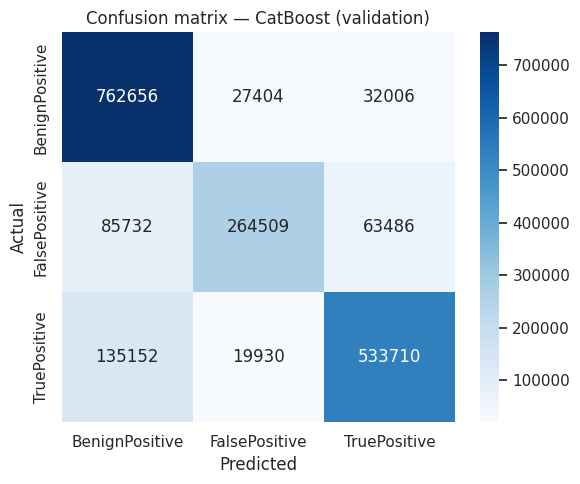

In [8]:
y_pred = model.predict(X_val).ravel()
y_proba = model.predict_proba(X_val)

accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average='macro')
weighted_f1 = f1_score(y_val, y_pred, average='weighted')

labels_order = sorted(inv_target_map)
label_names = [inv_target_map[i] for i in labels_order]

report_dict = classification_report(
    y_val, y_pred, labels=labels_order, target_names=label_names, output_dict=True
)
print(classification_report(y_val, y_pred, labels=labels_order, target_names=label_names))
print(f'Accuracy: {accuracy:.4f}  Macro-F1: {macro_f1:.4f}  Weighted-F1: {weighted_f1:.4f}')
print(f'Best iteration: {best_iteration}  Training time: {training_time:.1f}s')

cm = confusion_matrix(y_val, y_pred, labels=labels_order)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix — CatBoost (validation)')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/confusion_matrix.png', dpi=120)
plt.show()

## 8. Save model, metadata, results, and validation probabilities

In [9]:
model.save_model(f'{OUT_DIR}/catboost_model.cbm')
joblib.dump(model, f'{OUT_DIR}/catboost_model.pkl')

with open(f'{OUT_DIR}/classification_report.json', 'w') as f:
    json.dump(report_dict, f, indent=2)

preprocessing_info = {
    'features': FEATURES,
    'cat_features': CAT_FEATURES,
    'numeric_features': NUMERIC_FEATURES,
    'categorical_cols_from_lightgbm': CATEGORICAL_COLS,
    'numeric_cols_from_lightgbm': NUMERIC_COLS,
    'excluded_id_cols': ID_LIKE_COLS,
    'excluded_leakage_cols': LEAKAGE_COLS,
    'reviewed_kept_cols': ['SuspicionLevel', 'LastVerdict'],
    'reviewed_kept_cols_note': 'Assumption carried over unchanged from the LightGBM notebook; '
                               'prediction-time availability of these verdict columns is not '
                               're-verified here and remains an open/unresolved question.',
    'group_cols': GROUP_COLS,
    'target_map': target_map,
    'missing_value_placeholder': 'Missing',
    'reused_split_source': 'guide-lightgbm-baseline/split_assignment.csv',
    'reused_feature_audit_source': 'guide-lightgbm-baseline/preprocessing_info.json',
}
with open(f'{OUT_DIR}/preprocessing_info.json', 'w') as f:
    json.dump(preprocessing_info, f, indent=2)

model_params = model.get_all_params()
with open(f'{OUT_DIR}/catboost_params.json', 'w') as f:
    json.dump(model_params, f, indent=2, default=str)

results = {
    'dataset_rows_after_cleaning': int(len(df)),
    'train_rows': int(train_mask.sum()),
    'val_rows': int(val_mask.sum()),
    'n_features': len(FEATURES),
    'n_cat_features': len(CAT_FEATURES),
    'n_numeric_features': len(NUMERIC_FEATURES),
    'training_time_seconds': round(training_time, 1),
    'iterations_requested': 1000,
    'best_iteration': int(best_iteration),
    'early_stopping_rounds': 50,
    'stopping_metric': 'TotalF1:average=Macro',
    'stopping_metric_best_score': best_score,
    'task_type_requested': 'CPU',
    'task_type_actual': actual_task_type,
    'max_ctr_complexity': 1,
    'accuracy': round(float(accuracy), 4),
    'macro_f1': round(float(macro_f1), 4),
    'weighted_f1': round(float(weighted_f1), 4),
    'per_class_report': report_dict,
    'confusion_matrix': cm.tolist(),
    'target_classes_order': label_names,
}
with open(f'{OUT_DIR}/results.json', 'w') as f:
    json.dump(results, f, indent=2)

val_predictions = val_row_ids.copy()
for i, cls in enumerate(label_names):
    val_predictions[f'proba_{cls}'] = y_proba[:, i]
val_predictions['y_true'] = y_val.reset_index(drop=True).map(inv_target_map)
val_predictions['y_pred'] = pd.Series(y_pred).map(inv_target_map)
val_predictions.to_csv(f'{OUT_DIR}/val_predictions.csv', index=False)

lap('Saved catboost_model.cbm/.pkl, preprocessing_info.json, catboost_params.json, '
    'results.json, classification_report.json, confusion_matrix.png, val_predictions.csv')
print(json.dumps({k: v for k, v in results.items() if k not in ('per_class_report', 'confusion_matrix')}, indent=2))

[ 4983.5s] Saved catboost_model.cbm/.pkl, preprocessing_info.json, catboost_params.json, results.json, classification_report.json, confusion_matrix.png, val_predictions.csv
{
  "dataset_rows_after_cleaning": 9442956,
  "train_rows": 7518371,
  "val_rows": 1924585,
  "n_features": 19,
  "n_cat_features": 16,
  "n_numeric_features": 3,
  "training_time_seconds": 4793.5,
  "iterations_requested": 1000,
  "best_iteration": 342,
  "early_stopping_rounds": 50,
  "stopping_metric": "TotalF1:average=Macro",
  "stopping_metric_best_score": {
    "learn": {
      "TotalF1:average=Macro": 0.7957524704111005,
      "MultiClass": 0.4281996330368753
    },
    "validation": {
      "TotalF1:average=Macro": 0.7945845484117945,
      "MultiClass": 0.4368633524562894
    }
  },
  "task_type_requested": "CPU",
  "task_type_actual": "CPU",
  "max_ctr_complexity": 1,
  "accuracy": 0.811,
  "macro_f1": 0.7946,
  "weighted_f1": 0.8074,
  "target_classes_order": [
    "BenignPositive",
    "FalsePositive",
 

## 9. Summary & limitations

- Dataset, cleaning, leakage review, and train/validation split are all **reused exactly** from `guide-lightgbm-baseline` (verified: row counts match after the split lookup, and `(OrgId, IncidentId)` group overlap between train/val is re-checked as zero here).
- Same 19 audited raw features as LightGBM and Logistic Regression. CatBoost uses its own native categorical handling (`cat_features`) directly on the raw string-cast values — no one-hot encoding, no manual scaling — so this is the most "feature-policy-faithful" of the three baselines relative to LightGBM; the only representational choice made here is treating `DetectorId`/`AlertTitle`/`CountryCode`/`State`/`City` as categorical rather than ordinal, same as the other two notebooks' respective treatments of those columns.
- `SuspicionLevel`/`LastVerdict` prediction-time availability remains an **unresolved, unverified assumption** carried over from the LightGBM notebook — flagged again here rather than re-litigated, since re-auditing it was out of scope for this task.
- `max_ctr_complexity=1` was set specifically to avoid the categorical-combination blowup that made a separate earlier CatBoost run (inside the now-cancelled ensemble notebook) impractically slow; this is a resource-conscious setting, not a tuned hyperparameter, and no search over it (or depth/learning_rate/iterations) was performed per the task's scope.
- `best_iteration`/`early_stopping_rounds=50`/`use_best_model=True` mean training may have stopped well before the requested `iterations=1000` cap — see `results.json` for the actual value reached.
- `task_type` was explicitly requested and run as `'CPU'` (`enable_gpu=false` in this kernel's metadata, so no GPU was ever available to fall back to or report).
- The official test set was not touched in this notebook.